# Sensing Geometry of the OSSE Sounders

The OSSE examples ([monsoon](RunOSSEMonsoon.ipynb), [hurricane](RunOSSEHurricane.ipynb), and [cold pools](RunOSSEColdPools.ipynb)) compare four atmospheric sounders: the Advanced Technology Microwave Sounder (ATMS) and the Cross-track Infrared Sounder (CrIS) on the current NOAA/NASA polar-orbiting satellites, and a notional future microwave sounder and future infrared sounder with finer resolution. Their results follow from the sensors' **sensing geometry**: how each scans across the ground track, how large its footprints are and how they are spaced, how both grow away from nadir, and how wide a swath it covers. This notebook visualizes that geometry with TAT-C, for the sensors as the OSSEs model them.

The steps are:

1. configure a satellite (NOAA-20) and the sensors: the swaths and samples of ATMS and CrIS from TAT-C's instrument catalog, and the future sensors as the OSSEs define them;
2. tabulate the geometry of each sensor;
3. draw the scan in a vertical plane across the ground track, to scale;
4. plot the size of each sensor's footprints across its scan;
5. draw the footprints of consecutive scans on the ground, at nadir and at the edge of the swath;
6. map a day of swaths, with the study regions of the OSSEs;
7. view one pass in three dimensions, as the scans sweep out the swaths;
8. animate the ground tracks and swaths of the constellation (NOAA-20 and NOAA-21); and
9. animate, over one day, the swaths that the constellation's ATMS sweeps in a few minutes, on globes of the day and night sides of the Earth.

It requires the optional dependencies for OSSE examples (`pip install tatc[osse]`) and downloads no data.

## Configure the Satellite and Sensors

The satellite is NOAA-20, with the element set of the monsoon OSSE (epoch 16 July 2026). The figures use its first ascending (daytime) pass over the equator after the epoch.

**ATMS** scans 96 beam positions across the track every 8/3 s, spaced by 1.11 degrees. Its channels have beams of three widths: 5.2 degrees (channels 1 and 2), 2.2 degrees (channels 3 to 16, the temperature sounding channels), and 1.1 degrees (channels 17 to 22, the humidity sounding channels). The OSSEs use the 2.2 degree beams (32 km at nadir). **CrIS** steps across 30 fields of regard every 8 s, each imaged by a 3 x 3 array of circular fields of view of 0.963 degrees (14 km at nadir) at a pitch of 1.09 degrees, so neighboring views have small gaps between them. The catalog's configurations of their samples (`beams_noaa_20` of ATMS and `pixels` of CrIS) give these, and its swath configurations (`swath_noaa_20` and `swath`) the swaths between the outermost samples, scanning perpendicular to the inertial velocity.

The **future sensors** are those of the OSSEs: they share the swaths of ATMS and CrIS, with 10 km (microwave) and 3 km (infrared) footprints at nadir, sampled in proportion to their footprints in the ratio of their heritage sensors (5 km and 3.4 km). Each scans one row of samples, every time the ground track advances by its sample spacing.

In [1]:
from datetime import datetime, timedelta, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely

from tatc.analysis import (
    collect_ground_pixels,
    collect_orbit_track,
    compute_sample_sizes,
)
from tatc.catalog import get_entry
from tatc.constants import EARTH_MEAN_RADIUS
from tatc.schemas import GeneralPerturbationsOrbit, PointedInstrument
from tatc.utils import compute_ground_inertial_velocity

# NOAA-20's element set (epoch 2026-07-16 00:00 UTC), as in the monsoon OSSE
tle = [
    "1 43013U 17073A   26197.00000000  .00000069  00000-0  32863-4 0  1908",
    "2 43013  98.7768 136.2093 0001592 131.9807  15.3167 14.19516563448569",
]
orbit = GeneralPerturbationsOrbit.from_tle(tle)
epoch = datetime(2026, 7, 16, tzinfo=timezone.utc)
altitude = orbit.get_mean_altitude()
ground_speed = compute_ground_inertial_velocity(altitude) / 1e3  # km/s

entries = {"ATMS": get_entry("atms"), "CrIS": get_entry("cris")}
TIME_STEP = 30  # s, of the swaths
swath_satellites = {
    "ATMS": entries["ATMS"].to_satellite(
        orbit, configuration="swath_noaa_20", time_step=TIME_STEP, name="NOAA-20"
    ),
    "CrIS": entries["CrIS"].to_satellite(
        orbit, configuration="swath_noaa_20", time_step=TIME_STEP, name="NOAA-20"
    ),
}
atms_beams = entries["ATMS"].build(configuration="beams_noaa_20")
cris_pixels = entries["CrIS"].build(configuration="pixels_noaa_20")

# the first ascending equator crossing after the epoch (from the orbit track every 10 s)
probe = [epoch + timedelta(seconds=10 * i) for i in range(700)]
track = collect_orbit_track(swath_satellites["ATMS"], probe)
latitude = track.geometry.y.values
crossing = np.nonzero((latitude[:-1] < 0) & (latitude[1:] >= 0))[0][0]
t0 = track.time.iloc[crossing].to_pydatetime()
print(
    f"mean altitude {altitude / 1e3:.0f} km, ground speed {ground_speed:.2f} km/s; "
    f"ascending equator crossing at {t0:%Y-%m-%d %H:%M:%S} UTC, "
    f"{track.geometry.x.iloc[crossing]:.1f} deg longitude"
)

mean altitude 834 km, ground speed 6.58 km/s; ascending equator crossing at 2026-07-16 01:00:00 UTC, -172.6 deg longitude


Each sensor is a satellite with one instrument whose pixels are its samples (with the attitude of the catalog's configuration), and the time between its scans. The monsoon OSSE's `sensor_instrument` defines the future sensors, from the swath of their heritage sensor, their resolution at nadir, and their sample spacing, at the reference range of 830 km at which the nominal resolutions apply.

In [2]:
REFERENCE_RANGE_KM = 830
SENSORS = {  # sensor: (heritage swath, resolution at nadir in km)
    "ATMS": ("ATMS", 32),
    "CrIS": ("CrIS", 14),
    "Future MW": ("ATMS", 10),
    "Future IR": ("CrIS", 3),
}
ATMS_SOUNDING = 1  # index of the catalog's ATMS beams of channels 3 to 16 (2.2 degrees)
heritage_spacing = {  # angular spacing (deg) of the heritage samples across track
    "ATMS": atms_beams.instruments[ATMS_SOUNDING].cross_track_field_of_view
    / atms_beams.instruments[ATMS_SOUNDING].cross_track_pixels,
    "CrIS": cris_pixels.instruments[0].along_track_field_of_view
    / cris_pixels.instruments[0].along_track_pixels,
}


def future_instrument(swath, resolution_km):
    """A future sensor (as `sensor_instrument` of the monsoon OSSE): the swath of its heritage sensor, with pixels
    spaced in proportion to its footprint in the ratio of the heritage sensor, each with the instantaneous field of
    view that its resolution subtends at the reference range, and the time between its scans, in which the ground
    track advances by its sample spacing (so that its samples are spaced along track by that advance)."""
    instrument = swath_satellites[swath].instruments[0]
    heritage_km = SENSORS[swath][1]
    sampling_km = (
        REFERENCE_RANGE_KM
        * np.radians(heritage_spacing[swath])
        * resolution_km
        / heritage_km
    )
    ifov = np.degrees(2 * np.arctan(resolution_km / 2 / REFERENCE_RANGE_KM))
    spacing = np.degrees(sampling_km / REFERENCE_RANGE_KM)
    pixels = round(instrument.cross_track_field_of_view / spacing)
    scan_period = sampling_km / ground_speed
    return (
        PointedInstrument(
            **instrument.model_dump(
                exclude_unset=True,
                exclude={
                    "cross_track_field_of_view",
                    "along_track_field_of_view",
                    "cross_track_pixels",
                    "cross_track_oversampling",
                    "along_track_oversampling",
                    "is_swept",
                    "scan_period",
                },
            ),
            cross_track_field_of_view=pixels * spacing,
            along_track_field_of_view=spacing,
            cross_track_pixels=pixels,
            cross_track_oversampling=1 - spacing / ifov,
            along_track_oversampling=1 - spacing / ifov,
            scan_period=scan_period,
        ),
        scan_period,
    )


# each sensor's satellite (one instrument, whose pixels are its samples) and the time between its scans (s)
samplers = {
    "ATMS": (
        atms_beams.to_satellite(orbit, name="NOAA-20").model_copy(
            update={"instruments": [atms_beams.instruments[ATMS_SOUNDING]]}
        ),
        atms_beams.instruments[ATMS_SOUNDING].scan_period,
    ),
    "CrIS": (
        cris_pixels.to_satellite(orbit, name="NOAA-20"),
        cris_pixels.instruments[0].scan_period,
    ),
}
for sensor in ("Future MW", "Future IR"):
    swath, resolution_km = SENSORS[sensor]
    instrument, scan_period = future_instrument(swath, resolution_km)
    samplers[sensor] = (
        swath_satellites[swath].model_copy(update={"instruments": [instrument]}),
        scan_period,
    )
# the other ATMS channel groups, for comparison
for index, label in ((0, "ATMS 5.2 deg (ch. 1-2)"), (2, "ATMS 1.1 deg (ch. 17-22)")):
    samplers[label] = (
        samplers["ATMS"][0].model_copy(
            update={"instruments": [atms_beams.instruments[index]]}
        ),
        atms_beams.instruments[index].scan_period,
    )

## Tabulate the Geometry

`collect_ground_pixels` gives the center of each sample of one scan at the equator crossing, and `compute_sample_sizes` the size of each sample's footprint on the ground along and across track (the instantaneous field of view projected along the line of sight, which lengthens away from nadir and with the Earth's curvature), the spacing between neighboring samples, the slant range, and the scan angle. The table gives each sensor's scan, its footprint and the spacing of its samples (across and along track) at nadir and at the edge of the scan, the smallest feature it resolves there, and its swath width (between the outermost sample centers). Across track, the spacing is the angle between neighboring samples projected on the ground, so it grows in proportion to the footprint. Along track, it is the distance that the ground track advances between scans, divided among the rows of samples of a scan (one, or three for CrIS), which stays nearly constant across the scan, or the spacing of the rows within a scan where that is larger (CrIS toward the edge of its scan).

A sensor cannot resolve detail finer than either its footprint or the spacing between its samples, so its **resolution element** is the larger of the two, along and across track. As in the OSSEs, a feature is resolved if it spans at least `RESOLUTION_FACTOR` (two) resolution elements, with the size of an element measured as the diameter of a circle of the same area, so the **smallest resolved feature** is twice that diameter.

The rule is that of the OSSEs, but their model of ATMS and CrIS differs from the one here: like the future sensors, they model each as one row of samples at the angular pitch of its heritage samples (1.11 and 1.09 degrees), along and across track, without the advance between scans. Their smallest resolved features of CrIS are therefore smaller than those here, by 6% at nadir (32 km) and 8% at the edge of the scan (71 km), and those of ATMS differ by up to 3%.

In [3]:
def collect_scans(sensor, n_scans=1, start=None, mask=None):
    """The samples of a sensor's consecutive scans from a time (by default the equator crossing): their centers,
    times, scan, footprint and spacing (km, along and across track), slant range (km), and scan angle (deg).
    """
    satellite, scan_period = samplers[sensor]
    start = t0 if start is None else start
    times = [start + timedelta(seconds=scan_period * k) for k in range(n_scans)]
    pixels = collect_ground_pixels(satellite, times, mask=mask)
    pixels = compute_sample_sizes(
        pixels[pixels.valid_obs].reset_index(drop=True), satellite
    )
    for column in (
        "sample_along",
        "sample_cross",
        "spacing_along",
        "spacing_cross",
        "sat_range",
    ):
        pixels[column] = pixels[column] / 1e3
    pixels["scan"] = (pixels.time - pixels.time.min()).dt.total_seconds().round(3)
    return pixels


scans = {sensor: collect_scans(sensor) for sensor in samplers}

RESOLUTION_FACTOR = 2  # a feature is resolved if it spans at least this many resolution elements, as in the OSSEs


def smallest_feature(sample):
    """The diameter (km) of the smallest feature resolved at a sample, as in the OSSEs: RESOLUTION_FACTOR resolution
    elements, each the larger of the footprint and the spacing between samples, along and across track, measured as
    the diameter of a circle of the same area."""
    along = max(sample.sample_along, sample.spacing_along)
    cross = max(sample.sample_cross, sample.spacing_cross)
    return RESOLUTION_FACTOR * np.sqrt(along * cross)


def describe(sensor):
    """A sensor's geometry: the scan, samples per scan, and footprint and spacing at nadir and the edge."""
    s = scans[sensor]
    satellite, scan_period = samplers[sensor]
    instrument = satellite.instruments[0]
    nadir = s.loc[s.scan_angle.abs().idxmin()]
    edge = s.loc[s.scan_angle.abs().idxmax()]
    return pd.Series(
        {
            "scan (deg)": instrument.cross_track_field_of_view,
            "samples per scan": instrument.cross_track_pixels
            * instrument.along_track_pixels,
            "scan period (s)": scan_period,
            "nadir footprint (km)": nadir.sample_cross,
            "nadir spacing across (km)": nadir.spacing_cross,
            "nadir spacing along (km)": nadir.spacing_along,
            "edge scan angle (deg)": abs(edge.scan_angle),
            "edge slant range (km)": edge.sat_range,
            "edge footprint across (km)": edge.sample_cross,
            "edge footprint along (km)": edge.sample_along,
            "edge spacing across (km)": edge.spacing_cross,
            "edge spacing along (km)": edge.spacing_along,
            "smallest resolved feature, nadir (km)": smallest_feature(nadir),
            "smallest resolved feature, edge (km)": smallest_feature(edge),
            # the swath between the outermost sample centers, of the sensor's swath (the ATMS channels share one)
            "swath width (km)": swath_satellites[SENSORS.get(sensor, ("ATMS",))[0]]
            .instruments[0]
            .get_swath_width(altitude)
            / 1e3,
        }
    )


geometry_table = pd.DataFrame({sensor: describe(sensor) for sensor in samplers}).T
geometry_table.T.round(1)  # a row for each quantity, and a column for each sensor

,ATMS,CrIS,Future MW,Future IR,ATMS 5.2 deg (ch. 1-2),ATMS 1.1 deg (ch. 17-22)
scan (deg),106.8,100.0,105.6,96.6,106.8,106.8
samples per scan,96.0,270.0,304.0,413.0,96.0,96.0
scan period (s),2.7,8.0,0.8,0.5,2.7,2.7
nadir footprint (km),31.9,14.0,10.0,3.0,75.5,15.9
nadir spacing across (km),16.1,16.1,5.0,3.4,16.1,16.1
nadir spacing along (km),17.8,17.8,5.1,3.4,17.8,17.8
edge scan angle (deg),52.9,49.6,52.6,48.2,52.9,52.9
edge slant range (km),1585.3,1423.7,1573.1,1369.5,1585.3,1585.3
edge footprint across (km),140.8,46.9,43.2,9.2,338.3,70.2
edge footprint along (km),60.9,23.9,19.0,5.0,144.1,30.4


A cross-track scanner's footprint grows away from nadir for two reasons: the slant range to the ground lengthens (from about 830 km at nadir to 1,400 to 1,600 km at the edge of the scan), which widens the footprint in both directions, and the line of sight meets the ground obliquely, which stretches it further across track. At the edge of the scan, ATMS's 32 km footprints are about 140 km across track and 60 km along it, and CrIS's 14 km footprints about 47 by 24 km. The 5.2 degree beams of ATMS's lowest channels are about 340 km across at the edge.

### Overlapping and Separated Samples

The resolution element counts the **independent samples** across a feature. Where footprints overlap (spaced by less than their size), neighboring samples share much of the ground they see, so the footprint sets the size of an independent sample, and the extra samples add little detail. Where footprints are separated by gaps, each sample is independent but nothing is seen between them, so the spacing sets the size. Two elements are then about two independent samples across a feature, the least that can show its shape: on a regular grid of samples (with spacings along and across track within a factor of two of each other), a feature twice the spacing across always contains the centers of at least two samples, and about three (π) on average.

Taking the larger of the footprint and the spacing ignores the smaller one. That is fair where they differ by a factor of two, but optimistic where they are about equal, since both then degrade the image: the footprint blurs it, and the sampling aliases detail with a period shorter than twice the spacing. Adding the two in quadrature, as independent blurs, bounds the rule from the other side (it slightly penalizes the oversampled sensors, which their footprints alone limit). The table gives, for each sensor at nadir and at the edge of the scan, the ratio of the spacing to the footprint along and across track (below one, footprints overlap; above one, gaps separate them), the share of the ground inside a footprint (on a regular grid of the spacing), and the smallest resolved feature by the rule and in quadrature.

In [4]:
def ground_seen(sample, n=200):
    """The share of the ground inside a footprint, for elliptical footprints of a sample's size along and across
    track, on a regular grid of its spacing."""
    along, cross = np.meshgrid(
        (np.arange(n) + 0.5) / n * sample.spacing_along,
        (np.arange(n) + 0.5) / n * sample.spacing_cross,
    )
    inside = np.zeros(along.shape, dtype=bool)
    for i in range(-1, 3):
        for j in range(-1, 3):
            inside |= (
                ((along - i * sample.spacing_along) / (sample.sample_along / 2)) ** 2
                + ((cross - j * sample.spacing_cross) / (sample.sample_cross / 2)) ** 2
            ) <= 1
    return inside.mean()


def smallest_feature_quadrature(sample):
    """The diameter (km) of the smallest feature resolved at a sample with the footprint and the spacing added in
    quadrature along and across track (as independent blurs), rather than the larger of the two: the other bound."""
    along = np.hypot(sample.sample_along, sample.spacing_along)
    cross = np.hypot(sample.sample_cross, sample.spacing_cross)
    return RESOLUTION_FACTOR * np.sqrt(along * cross)


rows = {}
for sensor, s in scans.items():
    for where, sample in (
        ("nadir", s.loc[s.scan_angle.abs().idxmin()]),
        ("edge", s.loc[s.scan_angle.abs().idxmax()]),
    ):
        larger = smallest_feature(sample)
        quadrature = smallest_feature_quadrature(sample)
        rows[(sensor, where)] = {
            # below 1, neighboring footprints overlap; above 1, they are separated by gaps
            "spacing / footprint, along": sample.spacing_along / sample.sample_along,
            "spacing / footprint, across": sample.spacing_cross / sample.sample_cross,
            "ground inside a footprint (%)": 100 * ground_seen(sample),
            "smallest resolved feature (km)": larger,
            "in quadrature (km)": quadrature,
            "increase (%)": 100 * (quadrature / larger - 1),
        }
sampling_table = pd.DataFrame(rows).T
sampling_table.round(
    {column: 2 if column.startswith("spacing") else 1 for column in sampling_table}
)

spacing / footprint, along  \
ATMS                     nadir                        0.56   
                         edge                         0.29   
CrIS                     nadir                        1.27   
                         edge                         1.13   
Future MW                nadir                        0.51   
                         edge                         0.26   
Future IR                nadir                        1.14   
                         edge                         0.68   
ATMS 5.2 deg (ch. 1-2)   nadir                        0.24   
                         edge                         0.12   
ATMS 1.1 deg (ch. 17-22) nadir                        1.11   
                         edge                         0.57   

                                spacing / footprint, across  \
ATMS                     nadir                         0.51   
                         edge                          0.50   
CrIS                     nadir                         1.15   
                         edge                          1.15   
Future MW                nadir                         0.50   
                         edge                          0.50   
Future IR                nadir                         1.13   
                         edge                          1.13   
ATMS 5.2 deg (ch. 1-2)   nadir                         0.21   
                         edge                          0.21   
ATMS 1.1 deg (ch. 17-22) nadir                         1.01   
                         edge                          1.01   

                                ground inside a footprint (%)  \
ATMS                     nadir                          100.0   
                         edge                           100.0   
CrIS                     nadir                           53.5   
                         edge                            60.0   
Future MW                nadir                          100.0   
                         edge                           100.0   
Future IR                nadir                           60.8   
                         edge                            81.0   
ATMS 5.2 deg (ch. 1-2)   nadir                          100.0   
                         edge                           100.0   
ATMS 1.1 deg (ch. 17-22) nadir                           69.8   
                         edge                            93.2   

                                smallest resolved feature (km)  \
ATMS                     nadir                            63.8   
                         edge                            185.2   
CrIS                     nadir                            33.8   
                         edge                             76.7   
Future MW                nadir                            20.0   
                         edge                             57.2   
Future IR                nadir                             6.8   
                         edge                             14.3   
ATMS 5.2 deg (ch. 1-2)   nadir                           150.9   
                         edge                            441.5   
ATMS 1.1 deg (ch. 17-22) nadir                            33.8   
                         edge                             93.0   

                                in quadrature (km)  increase (%)  
ATMS                     nadir                72.3          13.2  
                         edge                199.9           7.9  
CrIS                     nadir                43.9          29.7  
                         edge                101.9          32.8  
Future MW                nadir                22.4          12.1  
                         edge                 61.6           7.6  
Future IR                nadir                 9.1          33.2  
                         edge                 18.2          27.2  
ATMS 5.2 deg (ch. 1-2)   nadir               154.7           2.5  
                         edge 

The microwave sounders overlap. The footprints of ATMS's 2.2 degree beams and of a future microwave sounder are spaced by about half their size (0.50 to 0.56 at nadir), so they see all of the ground, their footprints set their resolution, and adding the spacing in quadrature enlarges their smallest resolved feature by only 8 to 13%. The infrared sounders are separated. The views of CrIS are spaced by 1.15 times their size across track and 1.27 times along track at nadir (where its three rows share the 53 km advance of each 8 s scan), so that only 54% of the ground lies inside a view, and those of a future infrared sounder by 1.13 to 1.14 times (61%). Their spacing sets their resolution, but it is so near their footprint that both matter, and in quadrature their smallest resolved features grow by 27 to 33%. The 1.1 degree beams of ATMS's humidity channels, spaced by their own width, are the most uncertain (38% at nadir).

Where the footprint and the spacing are similar, then, the smallest resolved feature is uncertain by about a third, and the rule of the OSSEs (the larger of the two) favors the infrared sounders over the microwave sounders: in quadrature, the smallest resolved feature of CrIS at nadir is twice that of a future microwave sounder (44 and 22 km), rather than 1.7 times (34 and 20 km).

Across track, the footprints and the spacing grow in proportion away from nadir (their ratio is the same at the edge of the scan), but along track the footprints lengthen with the slant range while the advance between scans stays nearly constant, so the samples overlap more along track toward the edge of the scan. The views of a future infrared sounder, separated at nadir, overlap along track at the edge (5.0 km views, 3.4 km apart), as do the 1.1 degree beams of ATMS. CrIS is the exception: its three rows of views are spaced by an angle, so they spread with the slant range as its views lengthen, and stay separated along track (24 km views, 27 km apart).

## Draw the Scan Across the Track

The figure draws the plane of the scan across the ground track, to scale, over a spherical Earth: the lines of sight to the outermost samples of ATMS and CrIS, and the 2.2 degree beam of ATMS at nadir and at the edge of its scan. The Earth curves away beneath the swath, so the outermost samples are seen at a zenith angle well beyond the scan angle.

The boxes give the properties of the catalog's configurations of ATMS (`beams_noaa_20` and `swath_noaa_20`) and CrIS (`pixels_noaa_20` and `swath_noaa_20`) that set their scans, each with its provenance in the catalog: fitted to NOAA-20's geolocation (in the validation of the catalog), nominal (from the instrument's design), or derived from the others. The spacing of ATMS's beams (1.112 degrees) and of CrIS's fields of regard (3.334 degrees) are fitted so that the outermost samples fall where NOAA-20's geolocation places them, and the pitch of CrIS's views (1.0918 degrees) so that its three rows do; the small rolls shift each scan off nadir to match the slight asymmetry of its outermost samples, and the scan plane of CrIS tilts 0.223 degrees forward. The swaths, between the outermost beams of ATMS and the outermost centers of the fields of regard of CrIS, are measured directly. The arcs give the scan angle from nadir to the outermost samples (for CrIS, its outermost views, beyond the centers of its outermost fields of regard).

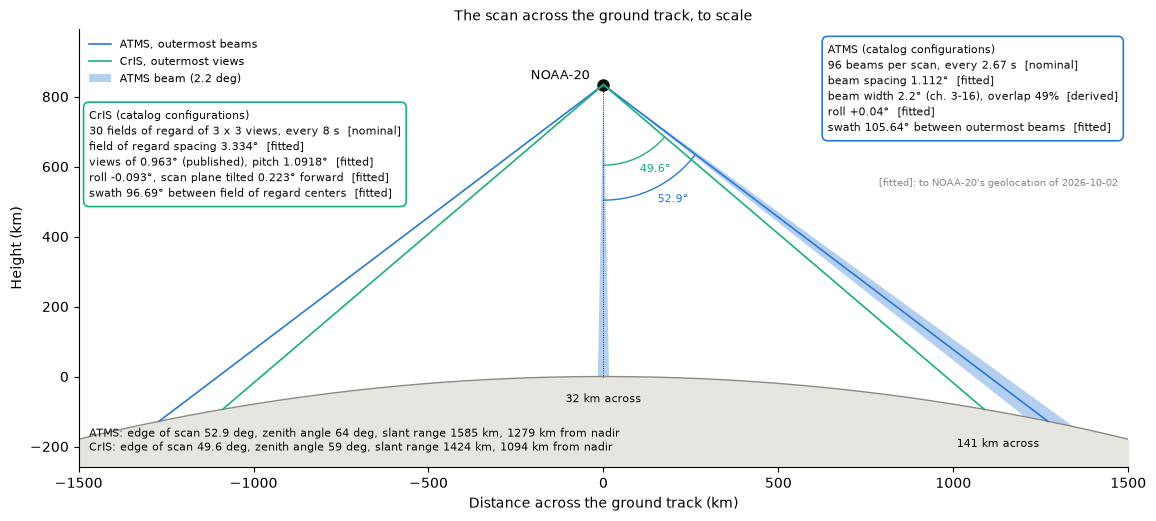

In [5]:
from matplotlib.patches import Arc

BLUE, ORANGE, AQUA, YELLOW, GRAY, INK = (
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#8a8984",
    "#0b0b0b",
)
SENSOR_COLORS = {"ATMS": BLUE, "Future MW": ORANGE, "CrIS": AQUA, "Future IR": YELLOW}
R, h = EARTH_MEAN_RADIUS / 1e3, altitude / 1e3


def ground_point(scan_angle):
    """The point (km across and above the surface at nadir) where a line of sight at a scan angle (deg) from the
    satellite meets a spherical Earth, and the Earth central angle (rad) to it."""
    eta = np.radians(scan_angle)
    central = np.arcsin((R + h) / R * np.sin(eta)) - eta
    return np.array([R * np.sin(central), R * np.cos(central) - R]), central


fig, ax = plt.subplots(figsize=(12, 5.2))
arc = np.linspace(-0.26, 0.26, 400)
ax.fill_between(R * np.sin(arc), R * np.cos(arc) - R, -400, color="#e6e5e0", lw=0)
ax.plot(R * np.sin(arc), R * np.cos(arc) - R, color=GRAY, lw=1)
satellite_xy = np.array([0, h])
ax.plot(*satellite_xy, marker="o", ms=8, color=INK)
ax.annotate(
    "NOAA-20",
    satellite_xy,
    xytext=(-10, 4),
    textcoords="offset points",
    fontsize=9,
    ha="right",
)
lines = []
for sensor in ("ATMS", "CrIS"):
    edge_angle = geometry_table.loc[sensor, "edge scan angle (deg)"]
    for sign in (-1, 1):
        point, central = ground_point(sign * edge_angle)
        ax.plot(
            *np.column_stack([satellite_xy, point]), color=SENSOR_COLORS[sensor], lw=1.2
        )
    point, central = ground_point(edge_angle)
    lines.append(
        f"{sensor}: edge of scan {edge_angle:.1f} deg, zenith angle {edge_angle + np.degrees(central):.0f} deg, "
        f"slant range {geometry_table.loc[sensor, 'edge slant range (km)']:.0f} km, "
        f"{R * central:.0f} km from nadir"
    )
ax.text(
    0.01,
    0.03,
    "\n".join(lines),
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=8,
    color=INK,
)
# the 2.2 degree beam of ATMS at nadir and at the edge of its scan
beam = atms_beams.instruments[ATMS_SOUNDING]
width = (
    beam.cross_track_field_of_view
    / beam.cross_track_pixels
    / (1 - beam.cross_track_oversampling)
)
edge_angle = geometry_table.loc["ATMS", "edge scan angle (deg)"]
for center, row, align in (
    (0, "nadir footprint (km)", "center"),
    (edge_angle, "edge footprint across (km)", "right"),
):
    near, _ = ground_point(center - width / 2)
    far, _ = ground_point(center + width / 2)
    ax.fill(*np.column_stack([satellite_xy, near, far]), color=BLUE, alpha=0.35, lw=0)
    point, _ = ground_point(center)
    ax.annotate(
        f"{geometry_table.loc['ATMS', row]:.0f} km across",
        point,
        xytext=(0 if align == "center" else -6, -12),
        textcoords="offset points",
        ha=align,
        va="top",
        fontsize=8,
        color=INK,
    )

# the half-angle of each scan, from nadir to its outermost samples (to the right)
for radius, sensor in ((330, "ATMS"), (230, "CrIS")):
    edge_angle = geometry_table.loc[sensor, "edge scan angle (deg)"]
    ax.add_patch(
        Arc(
            satellite_xy,
            2 * radius,
            2 * radius,
            theta1=270,
            theta2=270 + edge_angle,
            color=SENSOR_COLORS[sensor],
            lw=1,
        )
    )
    middle = np.radians(270 + edge_angle / 2)
    ax.text(
        *satellite_xy + (radius + 18) * np.array([np.cos(middle), np.sin(middle)]),
        f"{edge_angle:.1f}°",
        fontsize=8,
        color=SENSOR_COLORS[sensor],
        ha="left",
        va="top",
    )
ax.plot(*np.column_stack([satellite_xy, [0, 0]]), color=INK, lw=0.6, ls=":")

# the properties of the catalog's configurations of ATMS and CrIS, with their provenance: fitted to NOAA-20's
# geolocation (measured), nominal, or derived from the others
KIND = {"measured": "fitted", "nominal": "nominal", "derived": "derived"}


def provenance(sensor, configuration, parameter, index=0):
    """The provenance of a parameter of a configuration of a sensor in the catalog: fitted, nominal, or derived."""
    specification = entries[sensor].configurations[configuration].instruments[index]
    return KIND[specification.provenance[parameter].kind]


cris = cris_pixels.instruments[0]
cris_pitch = cris.along_track_field_of_view / cris.along_track_pixels
fitted_on = (
    entries["ATMS"]
    .configurations["beams_noaa_20"]
    .instruments[ATMS_SOUNDING]
    .provenance["roll_angle"]
    .period
)
properties = {
    "ATMS": [
        (
            f"{beam.cross_track_pixels} beams per scan, every {beam.scan_period:.2f} s",
            provenance("ATMS", "beams_noaa_20", "cross_track_pixels", ATMS_SOUNDING),
        ),
        (
            f"beam spacing {beam.cross_track_field_of_view / beam.cross_track_pixels:.3f}°",
            provenance(
                "ATMS", "beams_noaa_20", "cross_track_field_of_view", ATMS_SOUNDING
            ),
        ),
        (
            f"beam width {width:.1f}° (ch. 3-16), overlap {beam.cross_track_oversampling:.0%}",
            provenance(
                "ATMS", "beams_noaa_20", "cross_track_oversampling", ATMS_SOUNDING
            ),
        ),
        (
            f"roll {beam.roll_angle:+.2f}°",
            provenance("ATMS", "beams_noaa_20", "roll_angle", ATMS_SOUNDING),
        ),
        (
            f"swath {swath_satellites['ATMS'].instruments[0].cross_track_field_of_view:.2f}°"
            " between outermost beams",
            provenance("ATMS", "swath_noaa_20", "cross_track_field_of_view"),
        ),
    ],
    "CrIS": [
        (
            f"30 fields of regard of 3 x 3 views, every {cris.scan_period:.0f} s",
            provenance("CrIS", "pixels_noaa_20", "cross_track_pixels"),
        ),
        (
            f"field of regard spacing "
            f"{3 * cris.cross_track_field_of_view / cris.cross_track_pixels:.3f}°",
            provenance("CrIS", "pixels_noaa_20", "cross_track_field_of_view"),
        ),
        (
            f"views of {cris_pitch / (1 - cris.along_track_oversampling):.3f}° (published), pitch {cris_pitch:.4f}°",
            provenance("CrIS", "pixels_noaa_20", "along_track_field_of_view"),
        ),
        (
            f"roll {cris.roll_angle:+.3f}°, scan plane tilted {cris.pitch_angle:.3f}° forward",
            provenance("CrIS", "pixels_noaa_20", "roll_angle"),
        ),
        (
            f"swath {swath_satellites['CrIS'].instruments[0].cross_track_field_of_view:.2f}°"
            " between field of regard centers",
            provenance("CrIS", "swath_noaa_20", "cross_track_field_of_view"),
        ),
    ],
}
for (x, y, align), sensor in (
    ((0.99, 0.97, "right"), "ATMS"),
    ((0.01, 0.82, "left"), "CrIS"),
):
    ax.text(
        x,
        y,
        "\n".join(
            [f"{sensor} (catalog configurations)"]
            + [f"{text}  [{kind}]" for text, kind in properties[sensor]]
        ),
        transform=ax.transAxes,
        ha=align,
        va="top",
        multialignment="left",
        fontsize=8,
        color=INK,
        linespacing=1.4,
        bbox=dict(
            boxstyle="round,pad=0.5",
            facecolor="white",
            edgecolor=SENSOR_COLORS[sensor],
            lw=1.2,
        ),
    )
ax.text(
    0.99,
    0.66,
    f"[fitted]: to NOAA-20's geolocation of {fitted_on}",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=7.5,
    color=GRAY,
)

ax.plot([], [], color=BLUE, lw=1.2, label="ATMS, outermost beams")
ax.plot([], [], color=AQUA, lw=1.2, label="CrIS, outermost views")
ax.fill([], [], color=BLUE, alpha=0.35, lw=0, label=f"ATMS beam ({width:.1f} deg)")
ax.legend(loc="upper left", fontsize=8, frameon=False)
ax.set(
    xlim=(-1500, 1500),
    ylim=(-260, h + 160),
    aspect="equal",
    xlabel="Distance across the ground track (km)",
    ylabel="Height (km)",
)
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("The scan across the ground track, to scale", fontsize=10)
fig.tight_layout()
plt.show()

## Plot the Footprints Across the Scan

The figure gives the size of each sensor's footprint across the scan (one scan at the equator crossing), across track and along track, with ATMS's other channel groups in gray. The sizes are on a logarithmic scale, on which footprints that grow by the same factor away from nadir rise by the same height. From nadir to the edge of the scan, the footprints of the microwave sounders grow by a factor of about 4.4 across track and 1.9 along track, and those of the infrared sounders, whose scans are narrower, by about 3.2 and 1.7. Each future sensor's footprints stay the same fraction of its heritage sensor's across the swath, so its advantage in resolution holds everywhere in the swath, but the footprints of a future microwave sounder at the edge of its swath (43 by 19 km) are coarser than those of CrIS at nadir.

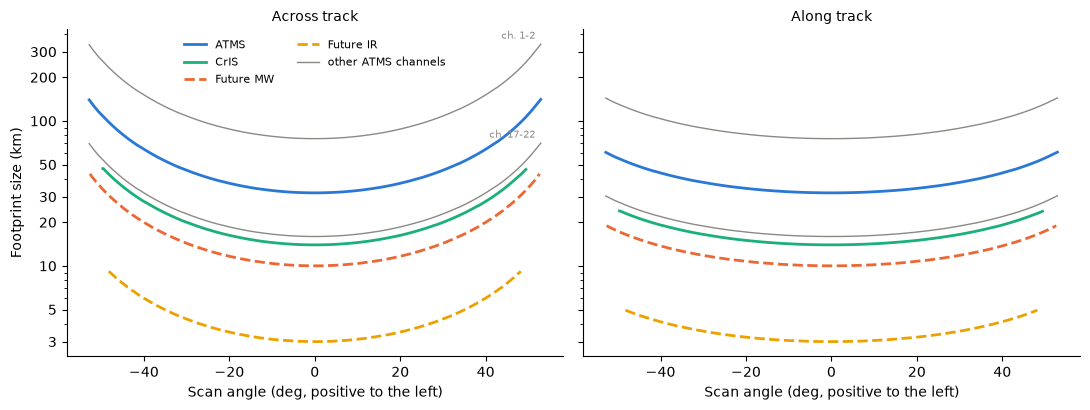

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
plt.rcParams.update({"axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6})
for ax, (column, title) in zip(
    axes, {"sample_cross": "Across track", "sample_along": "Along track"}.items()
):
    for sensor, s in scans.items():
        # one value per scan angle (CrIS has three rows of samples per scan)
        by_angle = s.groupby(s.scan_angle.round(1))[column].mean()
        heritage = sensor in SENSOR_COLORS
        ax.plot(
            by_angle.index,
            by_angle.values,
            color=SENSOR_COLORS.get(sensor, GRAY),
            lw=2 if heritage else 1,
            ls="-" if sensor in ("ATMS", "CrIS") or not heritage else "--",
            label=sensor if heritage else None,
        )
        if not heritage:
            ax.annotate(
                sensor.split(" (")[1][:-1] if column == "sample_cross" else "",
                (by_angle.index[-1], by_angle.values[-1]),
                xytext=(-4, 4),
                textcoords="offset points",
                ha="right",
                fontsize=7,
                color=GRAY,
            )
    ax.set(yscale="log", xlabel="Scan angle (deg, positive to the left)", title=title)
    ax.set_yticks(
        [3, 5, 10, 20, 30, 50, 100, 200, 300],
        ["3", "5", "10", "20", "30", "50", "100", "200", "300"],
    )
    ax.title.set_fontsize(10)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Footprint size (km)")
axes[0].plot([], [], color=GRAY, lw=1, label="other ATMS channels")
axes[0].legend(frameon=False, fontsize=8, loc="upper center", ncols=2)
fig.tight_layout()
plt.show()

## Draw the Footprints on the Ground

The figure draws the footprints of consecutive scans to scale, in a window of `WINDOW_KM` on a side at nadir (top) and at the edge of the scan (bottom), each footprint an ellipse of its size along and across track at its center. The dashed circle is the smallest feature resolved at the sample at the center of the window (see the table): the size that a feature must reach before the sensor can see its shape. Insets zoom on the footprints of the future sensors, which are too small to see at the scale of the window. The figure shows how each sensor tiles the ground: ATMS's beams overlap (each is twice the spacing between beam positions), CrIS's views leave gaps between them (about 2 km wide within a field of regard and 8 km between scans at nadir, so that nearly half of the ground lies between views), and the future sensors sample as their heritage sensors do, at a finer scale. At the edge of the scan, the footprints and the spacing between samples across track grow in proportion, but the scans are as far apart as at nadir (about 17.5 km for ATMS and 53 km for CrIS), so the longer footprints overlap more along track: ATMS's 61 km footprints span more than three scans, the three rows of CrIS's views overlap those of the next scan, and the views of a future infrared sounder overlap those of its neighboring scans. TAT-C places the rows of each field of regard of CrIS by their angle from the center of the scan (the frame geometry of the catalog's configuration), which at the edge of the scan brings them closer (24 km apart) than the angle between their lines of sight, from which the spacing in the tables is computed (27 km); in the figure, they appear contiguous along track there. The swath ends (the blank part of the window) at the outermost footprints.

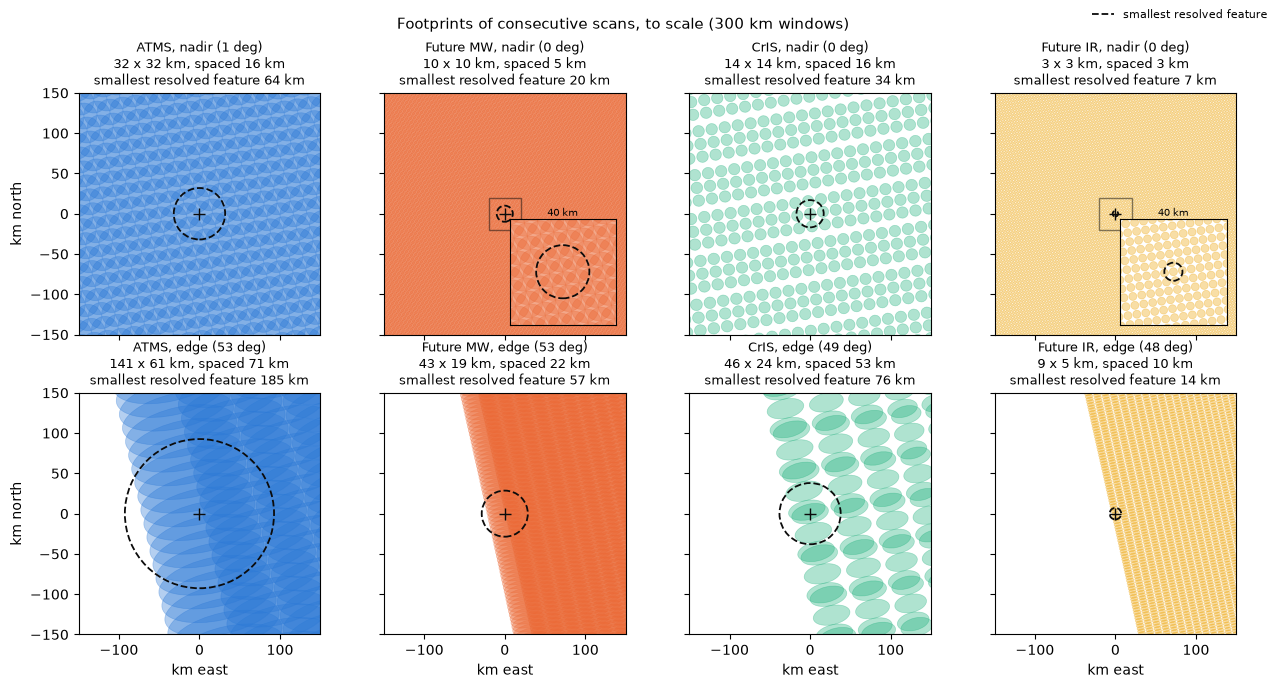

In [7]:
from matplotlib.collections import PatchCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Circle, Ellipse
from pyproj import Transformer

WINDOW_KM = 300  # km, the side of each window
INSET_KM = 40  # km, the side of the zoom on the footprints of the future sensors


def footprint_window(sensor, where):
    """The footprints (ellipses, km) of a sensor's consecutive scans in a window around its sample at nadir or at the
    edge of its scan, in an azimuthal equidistant projection centered on that sample."""
    satellite, scan_period = samplers[sensor]
    n_scans = int(np.ceil((WINDOW_KM + 200) / (ground_speed * scan_period))) + 1
    s = collect_scans(
        sensor, n_scans, start=t0 - timedelta(seconds=scan_period * (n_scans // 2))
    )
    middle = s[s.scan == np.sort(s.scan.unique())[n_scans // 2]]
    center = middle.loc[
        (
            middle.scan_angle.abs().idxmin()
            if where == "nadir"
            else middle.scan_angle.idxmax()
        )
    ]
    project = Transformer.from_crs(
        "EPSG:4326",
        f"+proj=aeqd +lat_0={center.geometry.y} +lon_0={center.geometry.x} +units=km",
        always_xy=True,
    )
    s["x"], s["y"] = project.transform(s.geometry.x.values, s.geometry.y.values)
    # the along-track direction of each sample: toward the same sample of the next scan
    s["index"] = s.groupby("scan").cumcount()
    following = s.set_index(["scan", "index"])[["x", "y"]]
    scans_sorted = np.sort(s.scan.unique())
    next_scan = dict(zip(scans_sorted[:-1], scans_sorted[1:]))
    next_scan[scans_sorted[-1]] = scans_sorted[-2]
    sign = np.where(s.scan == scans_sorted[-1], -1, 1)
    target = following.reindex(list(zip(s.scan.map(next_scan), s["index"]))).to_numpy()
    along = sign[:, None] * (target - s[["x", "y"]].to_numpy())
    s["angle"] = (
        np.degrees(np.arctan2(along[:, 1], along[:, 0])) - 90
    )  # of the across-track axis
    half = WINDOW_KM / 2 + 100
    return s[(s.x.abs() < half) & (s.y.abs() < half)]


fig, axes = plt.subplots(2, 4, figsize=(13, 6.8), sharex=True, sharey=True)
for column, sensor in enumerate(SENSOR_COLORS):
    for row, where in enumerate(("nadir", "edge")):
        ax = axes[row, column]
        w = footprint_window(sensor, where)
        ellipses = [
            Ellipse((x, y), width=cross, height=along, angle=angle)
            for x, y, cross, along, angle in zip(
                w.x, w.y, w.sample_cross, w.sample_along, w.angle
            )
        ]
        ax.add_collection(
            PatchCollection(
                ellipses,
                facecolor=SENSOR_COLORS[sensor],
                edgecolor=SENSOR_COLORS[sensor],
                alpha=0.35,
                linewidth=0.5,
            )
        )
        ax.plot(0, 0, marker="+", color=INK, ms=8)
        # the smallest feature resolved at the sample at the center of the window
        center = w.loc[(w.x**2 + w.y**2).idxmin()]
        feature_km = smallest_feature(center)
        ax.add_patch(
            Circle((0, 0), feature_km / 2, fill=False, edgecolor=INK, lw=1.3, ls="--")
        )
        if sensor.startswith("Future") and where == "nadir":
            # a zoom on the footprints, which are too small to see at the scale of the window
            inset = ax.inset_axes([0.52, 0.04, 0.44, 0.44])
            inset.add_collection(
                PatchCollection(
                    [
                        Ellipse((x, y), width=cross, height=along, angle=angle)
                        for x, y, cross, along, angle in zip(
                            w.x, w.y, w.sample_cross, w.sample_along, w.angle
                        )
                        if abs(x) < INSET_KM and abs(y) < INSET_KM
                    ],
                    facecolor=SENSOR_COLORS[sensor],
                    edgecolor=SENSOR_COLORS[sensor],
                    alpha=0.35,
                    linewidth=0.5,
                )
            )
            inset.set(
                xlim=(-INSET_KM / 2, INSET_KM / 2),
                ylim=(-INSET_KM / 2, INSET_KM / 2),
                aspect="equal",
                xticks=[],
                yticks=[],
            )
            inset.add_patch(
                Circle(
                    (0, 0), feature_km / 2, fill=False, edgecolor=INK, lw=1.3, ls="--"
                )
            )
            inset.set_title(f"{INSET_KM} km", fontsize=7, pad=2)
            ax.indicate_inset_zoom(inset, edgecolor=INK)
        ax.set_title(
            f"{sensor}, {where} ({abs(center.scan_angle):.0f} deg)\n"
            f"{center.sample_cross:.0f} x {center.sample_along:.0f} km, spaced {center.spacing_cross:.0f} km\n"
            f"smallest resolved feature {feature_km:.0f} km",
            fontsize=9,
        )
        ax.set(
            xlim=(-WINDOW_KM / 2, WINDOW_KM / 2),
            ylim=(-WINDOW_KM / 2, WINDOW_KM / 2),
            aspect="equal",
        )
        ax.grid(False)
for ax in axes[1]:
    ax.set_xlabel("km east")
for ax in axes[:, 0]:
    ax.set_ylabel("km north")
fig.suptitle(
    f"Footprints of consecutive scans, to scale ({WINDOW_KM} km windows)", fontsize=11
)
fig.legend(
    handles=[
        Line2D([], [], color=INK, lw=1.3, ls="--", label="smallest resolved feature")
    ],
    loc="upper right",
    fontsize=8,
    frameon=False,
)
fig.tight_layout()
plt.show()

## Map a Day of Swaths

The map shows NOAA-20's swaths of ATMS and CrIS on its daytime (ascending) passes over one day, within 75 degrees of the equator, with the study regions of the OSSEs. At the equator, consecutive passes are about 2,800 km apart, more than either swath is wide, so both leave gaps between passes there (wider for the narrower CrIS swath), which close toward higher latitudes as the passes converge. On this day, the swath of NOAA-20's pass at about 01:00 UTC reaches only the southern half of the EarthCARE frame of the cold pool OSSE, and a gap lies over its northern half, as in that OSSE (where NOAA-20's passes in its window cover 23 and 53% of the frame). Every daytime pass crosses the equator near 13:30 local time, so each region is observed at about that time (and again near 01:30 on the nighttime passes), which sets the timing of the observations in every OSSE. NOAA-21, the other satellite of the current constellation (since Suomi NPP was decommissioned), flies in the same orbit plane about half an orbit (55 minutes) from NOAA-20, and fills some of the gaps at the same local times.

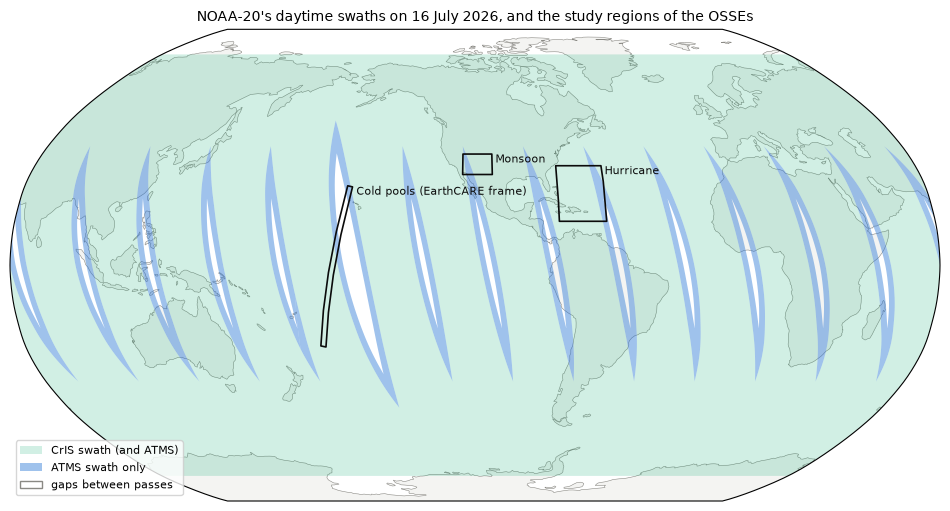

In [8]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from tatc.analysis import collect_ground_track

MAX_LATITUDE = 75  # deg, the swaths are mapped equatorward of it (near the poles, footprints span all longitudes)
times = [
    epoch + timedelta(seconds=TIME_STEP * (i + 0.5))
    for i in range(int(86400 / TIME_STEP))
]
# daytime passes ascend (northward) on the 13:30 orbit: from the latitude of the satellite at each time
subsatellite = collect_orbit_track(swath_satellites["ATMS"], times)
ascending = pd.Series(
    np.gradient(subsatellite.geometry.y.values) > 0, index=subsatellite.time
)
band = shapely.box(-180, -MAX_LATITUDE, 180, MAX_LATITUDE)
day_swaths = {}
for sensor, satellite in swath_satellites.items():
    track = collect_ground_track(satellite, times)
    track = track[track.valid_obs & ascending.reindex(track.time).values]
    day_swaths[sensor] = shapely.union_all(
        shapely.intersection(shapely.force_2d(track.geometry.values), band)
    )

REGIONS = {
    "Monsoon": shapely.box(-115, 31, -103, 38),
    "Hurricane": shapely.box(-77, 15, -58.5, 34),
    "Cold pools (EarthCARE frame)": shapely.Polygon(
        [(-169.73, -27.98), (-171.71, -27.62), (-160.9, 27.14), (-158.93, 26.77)]
    ),
}
fig, ax = plt.subplots(
    figsize=(12, 6.2), subplot_kw={"projection": ccrs.Robinson(central_longitude=-110)}
)
ax.set_global()
ax.add_feature(cfeature.LAND, facecolor="#f4f4f2")
ax.add_feature(cfeature.COASTLINE, edgecolor=GRAY, linewidth=0.4)
# the swath of CrIS, and the strips on either side that only the wider swath of ATMS covers (without the slivers of
# zero area that the difference leaves where the edges of the swaths meet: cartopy cannot orient a ring without area,
# and fills it as its complement, the rest of the globe)
atms_only = shapely.get_parts(day_swaths["ATMS"].difference(day_swaths["CrIS"]))
ax.add_geometries(
    atms_only[shapely.area(atms_only) > 1e-3],
    crs=ccrs.PlateCarree(),
    facecolor=BLUE,
    edgecolor="none",
    alpha=0.45,
)
ax.add_geometries(
    [day_swaths["CrIS"]],
    crs=ccrs.PlateCarree(),
    facecolor=AQUA,
    edgecolor="none",
    alpha=0.2,
)
for name, region in REGIONS.items():
    ax.add_geometries(
        [region], crs=ccrs.PlateCarree(), facecolor="none", edgecolor=INK, linewidth=1.2
    )
    x, y = region.bounds[2], region.bounds[3]
    ax.text(
        x + 1.5, y, name, transform=ccrs.PlateCarree(), fontsize=8, color=INK, va="top"
    )
ax.add_patch(
    plt.Rectangle(
        (0, 0), 0, 0, facecolor=AQUA, alpha=0.2, label="CrIS swath (and ATMS)"
    )
)
ax.add_patch(
    plt.Rectangle((0, 0), 0, 0, facecolor=BLUE, alpha=0.45, label="ATMS swath only")
)
ax.add_patch(
    plt.Rectangle(
        (0, 0), 0, 0, facecolor="white", edgecolor=GRAY, label="gaps between passes"
    )
)
ax.legend(loc="lower left", fontsize=8)
ax.set_title(
    f"NOAA-20's daytime swaths on {epoch:%d %B %Y}, and the study regions of the OSSEs",
    fontsize=10,
)
plt.show()

## View a Pass in Three Dimensions

The map flattens the swaths onto the ground. The figure shows how they arise, in three dimensions and to scale, over the ascending pass of the figures above: `PASS_MINUTES` minutes either side of the equator crossing, as NOAA-20 flies north over the central Pacific from 32°S to 32°N, 7,100 km along its ground track. At the equator crossing, it draws the scan of each sensor: the lines of sight from the satellite to the samples of one scan (as in the scan across the ground track, above), which meet the ground in a line across the ground track. As the satellite advances, its scans sweep that line along the track into a swath, 2,550 km wide for ATMS and 2,070 km for CrIS, within it. To scale, ATMS's swath is three times as wide as the satellite is high, and the Earth curves away beneath it: the edges of the swaths lie about 125 km (ATMS) and 90 km (CrIS) below the horizontal plane at nadir, and the orbit itself, which follows the Earth's curvature, lies nearly 300 km below that plane at either end of the pass.

The ground track (dashed) runs north-northwest, while the EarthCARE frame of the cold pool OSSE, which follows EarthCARE's ground track, runs north-northeast. The frame lies within both swaths at its southern end and leaves CrIS's swath north of about 7°N and ATMS's north of about 13°N, short of Hawaii, so this pass covers 60% of the frame with CrIS and 70% with ATMS.

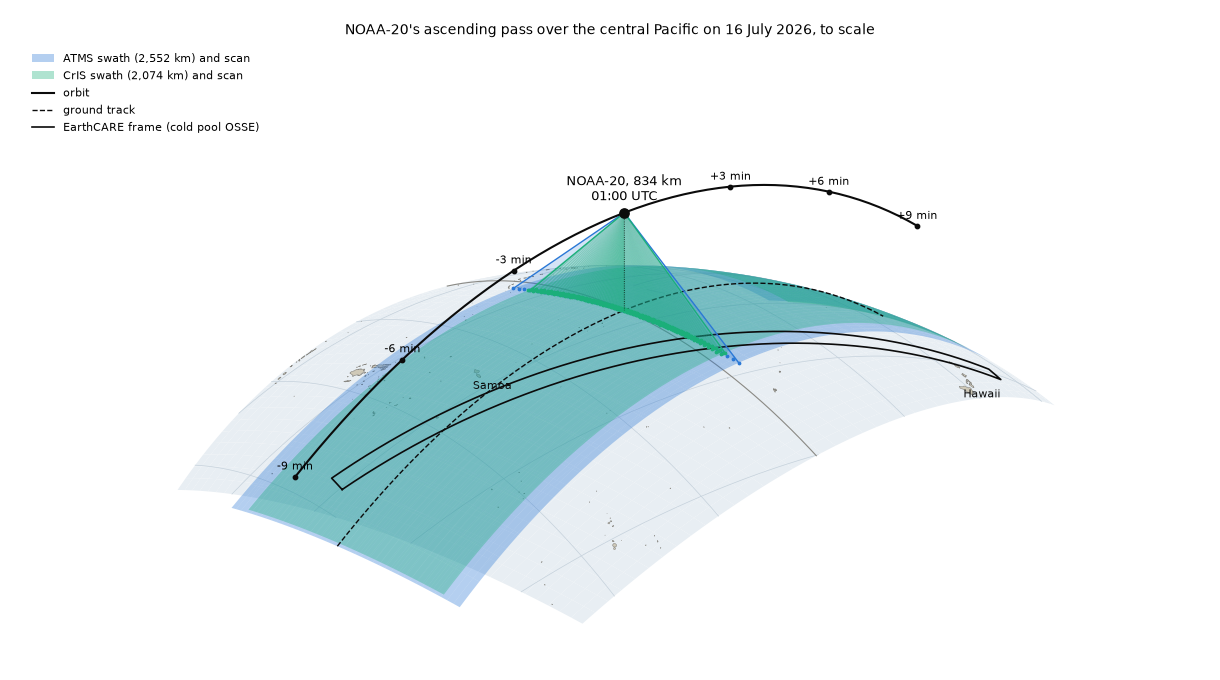

In [9]:
import shapely.affinity
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

PASS_MINUTES = 9  # min, before and after the equator crossing (spanning the frame)
PASS_STEP = 20  # s, between the scans that outline the swaths
PATCH_KM = 2600  # km, the half-width of the patch of the Earth drawn beneath the pass
to_ecef = Transformer.from_crs("EPSG:4326", "EPSG:4978", always_xy=True)
to_lonlat = Transformer.from_crs("EPSG:4978", "EPSG:4326", always_xy=True)


def ecef(lon, lat, height=0.0):
    """The Earth-fixed coordinates (km) of points at a height (km) above the WGS 84 ellipsoid."""
    lon, lat = np.broadcast_arrays(lon, lat)
    x, y, z = to_ecef.transform(lon, lat, np.full(lon.shape, height * 1e3))
    return np.stack([x, y, z], axis=-1) / 1e3


def drape(points):
    """Points (km, Earth-fixed) moved along the ellipsoid's normal onto the ellipsoid, and their longitude and
    latitude."""
    lon, lat, _ = to_lonlat.transform(*(np.moveaxis(points, -1, 0) * 1e3))
    return ecef(lon, lat), lon, lat


# the satellite's positions (Earth-fixed) and the points beneath it over the pass
pass_times = [
    t0 + timedelta(seconds=s)
    for s in range(-60 * PASS_MINUTES, 60 * PASS_MINUTES + 1, PASS_STEP)
]
noaa_20 = samplers["ATMS"][0]
positions = collect_orbit_track(noaa_20, pass_times, coordinates="ecef")
satellite_ecef = (
    np.column_stack([positions.geometry.x, positions.geometry.y, positions.geometry.z])
    / 1e3
)
subsatellite = collect_orbit_track(noaa_20, pass_times)
# longitudes continuous across the antimeridian
nadir_lon = np.unwrap(subsatellite.geometry.x.values, period=360)
nadir_lat = subsatellite.geometry.y.values

# the scene's frame: centered on the point beneath the satellite at the equator crossing, with x across the ground
# track (to its right, east), y along it (north), and z up
k0 = pass_times.index(t0)
origin = ecef(nadir_lon[k0], nadir_lat[k0])
up = origin / np.linalg.norm(origin)
forward = ecef(nadir_lon[k0 + 1], nadir_lat[k0 + 1]) - ecef(
    nadir_lon[k0 - 1], nadir_lat[k0 - 1]
)
forward = forward - forward.dot(up) * up
forward /= np.linalg.norm(forward)
axes_3d = np.stack([np.cross(forward, up), forward, up])


def scene(points):
    """Earth-fixed points (km) in the scene's frame."""
    return (np.asarray(points) - origin) @ axes_3d.T


def swath_surface(sensor, n_across=41):
    """The ground (km, scene frame) between the outermost samples of a sensor's scans over the pass."""
    satellite, _ = samplers[sensor]
    pixels = collect_ground_pixels(satellite, pass_times)
    pixels = compute_sample_sizes(
        pixels[pixels.valid_obs].reset_index(drop=True), satellite
    )
    edges = []
    for _, scan in pixels.groupby("time"):
        # positive scan angles to the left
        left = scan.loc[scan.scan_angle.idxmax()].geometry
        right = scan.loc[scan.scan_angle.idxmin()].geometry
        edges.append([ecef(left.x, left.y), ecef(right.x, right.y)])
    edges = np.array(edges)
    fraction = np.linspace(0, 1, n_across)[None, :, None]
    return scene(drape(edges[:, :1] * (1 - fraction) + edges[:, 1:] * fraction)[0])


satellite_xyz = scene(satellite_ecef)
track_xyz = scene(ecef(nadir_lon, nadir_lat))
# the patch of the Earth beneath the pass: a grid in the scene's frame, draped onto the ellipsoid
along_min, along_max = track_xyz[:, 1].min() - 300, track_xyz[:, 1].max() + 300
grid_x, grid_y = np.meshgrid(
    np.linspace(-PATCH_KM, PATCH_KM, 40), np.linspace(along_min, along_max, 80)
)
patch_points, patch_lon, patch_lat = drape(
    origin + np.stack([grid_x, grid_y, np.zeros_like(grid_x)], axis=-1) @ axes_3d
)
# continuous longitudes, in the same turn as those of the ground track
patch_lon = np.unwrap(np.unwrap(patch_lon, period=360, axis=1), period=360, axis=0)
patch_lon -= 360 * np.round(
    (patch_lon[tuple(np.array(patch_lon.shape) // 2)] - nadir_lon[k0]) / 360
)
patch = scene(patch_points)
outline = np.concatenate(
    [
        np.column_stack([patch_lon[0], patch_lat[0]]),
        np.column_stack([patch_lon[:, -1], patch_lat[:, -1]]),
        np.column_stack([patch_lon[-1, ::-1], patch_lat[-1, ::-1]]),
        np.column_stack([patch_lon[::-1, 0], patch_lat[::-1, 0]]),
    ]
)
patch_shape = shapely.Polygon(outline)

# the 3D axes are square, and the scene wide and low: the axes extend beyond the figure, which crops their margins,
# and the figure is shown within its own bounds rather than those of the axes
fig = plt.figure(figsize=(12, 6.6))
ax = fig.add_axes((-0.1, -0.3, 1.2, 1.62), projection="3d", computed_zorder=False)
ax.get_tightbbox = lambda *args, **kwargs: fig.bbox
# matplotlib draws the layers in the order of their zorder rather than by depth, which is right when they are seen
# from above: the Earth, the swaths, the frame, the ground track, the scans, and the orbit
ax.plot_surface(
    *np.moveaxis(patch, -1, 0), color="#e8eef3", shade=False, lw=0, zorder=0
)


def draw_on_ground(lon, lat, **kwargs):
    """A line on the ground (longitude and latitude, deg), within the patch."""
    line = shapely.intersection(
        shapely.LineString(np.column_stack([lon, lat])), patch_shape
    )
    for part in shapely.get_parts(line):
        lon_lat = np.asarray(part.coords)
        ax.plot(*scene(ecef(lon_lat[:, 0], lon_lat[:, 1])).T, **kwargs)


# a graticule every 10 degrees, with the equator
west, south, east, north = patch_shape.bounds
for lon in np.arange(np.ceil(west / 10) * 10, east, 10):
    draw_on_ground(
        np.full(200, lon),
        np.linspace(south, north, 200),
        color="#c5d1db",
        lw=0.5,
        zorder=0.1,
    )
for lat in np.arange(np.ceil(south / 10) * 10, north, 10):
    draw_on_ground(
        np.linspace(west, east, 200),
        np.full(200, lat),
        color=GRAY if lat == 0 else "#c5d1db",
        lw=0.8 if lat == 0 else 0.5,
        zorder=0.1,
    )
# the islands beneath the pass, from the Natural Earth land (whose longitudes are within 180 degrees)
land = cfeature.NaturalEarthFeature("physical", "land", "10m")
for shift in (-360, 0, 360):
    window = shapely.affinity.translate(patch_shape, -shift).intersection(
        shapely.box(-180, -90, 180, 90)
    )
    if window.is_empty:
        continue
    for geometry in land.intersecting_geometries(
        np.asarray(window.bounds)[[0, 2, 1, 3]]
    ):
        for part in shapely.get_parts(
            shapely.affinity.translate(geometry.intersection(window), shift)
        ):
            if isinstance(part, shapely.Polygon) and part.area > 1e-4:
                ring = np.asarray(part.exterior.coords)
                ax.add_collection3d(
                    Poly3DCollection(
                        [scene(ecef(ring[:, 0], ring[:, 1]))],
                        facecolor="#cfc9b8",
                        edgecolor=GRAY,
                        lw=0.4,
                        zorder=0.2,
                    )
                )
for label, lon, lat in (("Hawaii", -155.5, 19.2), ("Samoa", -171.5, -14.6)):
    ax.text(
        *scene(ecef(lon, lat)),
        label,
        fontsize=8,
        color=INK,
        ha="left",
        va="top",
        zorder=9,
    )

# the swaths (CrIS's within ATMS's), and the EarthCARE frame of the cold pool OSSE
for layer, sensor in enumerate(("ATMS", "CrIS")):
    ax.plot_surface(
        *np.moveaxis(swath_surface(sensor), -1, 0),
        color=SENSOR_COLORS[sensor],
        alpha=0.35,
        shade=False,
        lw=0,
        zorder=1 + layer,
    )
frame_ring = np.asarray(
    shapely.segmentize(REGIONS["Cold pools (EarthCARE frame)"], 0.5).exterior.coords
)
draw_on_ground(frame_ring[:, 0], frame_ring[:, 1], color=INK, lw=1.2, zorder=3)

# the ground track and the orbit, with the satellite's position every 3 minutes
ax.plot(*track_xyz.T, color=INK, lw=1, ls="--", zorder=4)
ax.plot(*satellite_xyz.T, color=INK, lw=1.5, zorder=7)
for minutes in range(-PASS_MINUTES + PASS_MINUTES % 3, PASS_MINUTES + 1, 3):
    if minutes == 0:
        continue
    k = pass_times.index(t0 + timedelta(minutes=minutes))
    ax.scatter(*satellite_xyz[k], s=10, color=INK, depthshade=False, zorder=7)
    ax.text(
        *satellite_xyz[k] + [0, 0, 60],
        f"{minutes:+d} min",
        fontsize=8,
        ha="center",
        zorder=9,
    )

# the scan of each sensor at the equator crossing: the lines of sight from the satellite to its samples
satellite_0 = satellite_xyz[k0]
for layer, sensor in enumerate(("ATMS", "CrIS")):
    s = scans[sensor].sort_values("scan_angle")
    samples = scene(ecef(s.geometry.x.values, s.geometry.y.values))
    ax.add_collection3d(
        Poly3DCollection(
            [[satellite_0, a, b] for a, b in zip(samples[:-1], samples[1:])],
            facecolor=SENSOR_COLORS[sensor],
            edgecolor="none",
            alpha=0.2,
            zorder=5 + layer / 2,
        )
    )
    for sample in (samples[0], samples[-1]):
        ax.plot(
            *np.column_stack([satellite_0, sample]),
            color=SENSOR_COLORS[sensor],
            lw=1,
            zorder=6,
        )
    ax.scatter(*samples.T, s=3, color=SENSOR_COLORS[sensor], depthshade=False, zorder=6)
ax.plot(
    *np.column_stack([satellite_0, track_xyz[k0]]), color=INK, lw=0.6, ls=":", zorder=6
)
ax.scatter(*satellite_0, s=45, color=INK, depthshade=False, zorder=8)
ax.text(
    *satellite_0 + [0, 0, 70],
    f"NOAA-20, {altitude / 1e3:.0f} km\n{t0:%H:%M} UTC",
    fontsize=9,
    ha="center",
    va="bottom",
    zorder=9,
)

ax.set(xlim=(-PATCH_KM, PATCH_KM), ylim=(along_min, along_max))
ax.set_zlim(patch[..., 2].min(), satellite_xyz[:, 2].max() + 200)
ax.set_box_aspect(
    [np.ptp(ax.get_xlim()), np.ptp(ax.get_ylim()), np.ptp(ax.get_zlim())], zoom=1.05
)
ax.view_init(elev=20, azim=-50)
ax.set_axis_off()
swath_km = geometry_table["swath width (km)"]
fig.legend(
    handles=[
        plt.Rectangle(
            (0, 0),
            0,
            0,
            facecolor=BLUE,
            alpha=0.35,
            label=f"ATMS swath ({swath_km['ATMS']:,.0f} km) and scan",
        ),
        plt.Rectangle(
            (0, 0),
            0,
            0,
            facecolor=AQUA,
            alpha=0.35,
            label=f"CrIS swath ({swath_km['CrIS']:,.0f} km) and scan",
        ),
        Line2D([], [], color=INK, lw=1.5, label="orbit"),
        Line2D([], [], color=INK, lw=1, ls="--", label="ground track"),
        Line2D([], [], color=INK, lw=1.2, label="EarthCARE frame (cold pool OSSE)"),
    ],
    loc="upper left",
    bbox_to_anchor=(0.01, 0.95),
    fontsize=8,
    frameon=False,
)
fig.suptitle(
    f"NOAA-20's ascending pass over the central Pacific on {t0:%d %B %Y}, to scale",
    fontsize=10,
    y=0.98,
)
plt.show()

## Animate the Constellation's Ground Tracks

The current constellation of these sounders is NOAA-20 and NOAA-21 (since Suomi NPP was decommissioned), in the same sun-synchronous orbit plane about half an orbit apart. The animation follows both for `ANIMATION_HOURS` hours in steps of `FRAME_MINUTES`: each satellite's position, its ground track, and the swath of ATMS that it has covered over the last orbit (`TRAIL`), over the night side of the Earth (shaded). The swaths are translucent, so where they overlap their colors blend: a GIF has no partial transparency, but matplotlib blends the layers of each frame into opaque pixels before the frame is written. Each satellite's footprints are merged into one shape per frame, so that the frame has only a few flat colors, which compress well. Both cross the equator northward on the day side near 13:30 local time and southward on the night side near 01:30, about 55 minutes apart, so the swath of each falls between the passes of the other, and together they cover the gaps between one satellite's passes within about an hour. It is saved as a GIF in the `data` directory (it is not embedded here, for its size).

In [10]:
from pathlib import Path

from cartopy.feature.nightshade import Nightshade
from cartopy.mpl.path import shapely_to_path
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.collections import PathCollection
from matplotlib.colors import to_hex, to_rgb

DATA_DIR = Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)
ANIMATION_FILE = DATA_DIR / "constellation_ground_tracks.gif"
ANIMATION_HOURS = 6  # hours from the epoch
FRAME_MINUTES = 2  # minutes per frame of the animation
FPS = 15  # frames per second of the animation
TRAIL = timedelta(
    minutes=101
)  # the swath and ground track drawn behind each satellite (about one orbit)
CONSTELLATION = {  # element sets (epoch 2026-07-16 00:00 UTC), as in the OSSEs
    "NOAA-20": tle,
    "NOAA-21": [
        "1 54234U 22150A   26197.00000000  .00000063  00000-0  30079-4 0  9591",
        "2 54234  98.7055 135.3072 0002920 108.6153 233.8084 14.19541053190632",
    ],
}
SATELLITE_COLORS = {"NOAA-20": BLUE, "NOAA-21": ORANGE}
SWATH_ALPHA = 0.35  # the opacity of the swaths
SEAM_M = 500  # m, by which footprints are buffered so that neighboring ones merge without seams
projection = ccrs.Robinson(central_longitude=-110)

# each satellite's ATMS swath (footprints every TIME_STEP, within MAX_LATITUDE), projected once onto the map, and
# its subsatellite points, over the animation and the trail before it
constellation = {
    name: entries["ATMS"].to_satellite(
        GeneralPerturbationsOrbit.from_tle(elements),
        configuration="swath_noaa_20",
        time_step=TIME_STEP,
        name=name,
    )
    for name, elements in CONSTELLATION.items()
}
animation_times = [
    epoch - TRAIL + timedelta(seconds=TIME_STEP * (i + 0.5))
    for i in range(
        int((timedelta(hours=ANIMATION_HOURS) + TRAIL).total_seconds() / TIME_STEP)
    )
]
footprints, subpoints = {}, {}
for name, satellite in constellation.items():
    track = collect_ground_track(satellite, animation_times)
    track = track[track.valid_obs].reset_index(drop=True)
    clipped = shapely.intersection(shapely.force_2d(track.geometry.values), band)
    footprints[name] = pd.DataFrame(
        {
            "time": track.time,
            "shape": shapely.buffer(
                shapely.make_valid(
                    [
                        projection.project_geometry(footprint, ccrs.PlateCarree())
                        for footprint in clipped
                    ]
                ),
                SEAM_M,
            ),
        }
    )
    points = collect_orbit_track(satellite, animation_times)
    subpoints[name] = pd.DataFrame(
        {"time": points.time, "lon": points.geometry.x, "lat": points.geometry.y}
    )


def map_track(lon, lat):
    """A ground track in the map's coordinates, with a break (NaN) where it crosses the edge of the map (drawn in
    those coordinates, so that cartopy does not project a line with breaks)."""
    xy = projection.transform_points(
        ccrs.PlateCarree(), np.asarray(lon), np.asarray(lat)
    )
    x, y = xy[:, 0], xy[:, 1]
    width = projection.x_limits[1] - projection.x_limits[0]
    jumps = np.nonzero(np.abs(np.diff(x)) > width / 2)[0] + 1
    return np.insert(x, jumps, np.nan), np.insert(y, jumps, np.nan)


frame_times = [
    epoch + timedelta(minutes=FRAME_MINUTES * k)
    for k in range(int(ANIMATION_HOURS * 60 / FRAME_MINUTES) + 1)
]
fig, ax = plt.subplots(
    figsize=(10, 5.4), subplot_kw={"projection": projection}, layout="constrained"
)
ax.set_global()
ax.add_feature(cfeature.LAND, facecolor="#e6e5e0")
ax.add_feature(cfeature.COASTLINE, edgecolor=GRAY, linewidth=0.4, zorder=3)
swaths_drawn, trails, markers, shade = {}, {}, {}, []
for name, color in SATELLITE_COLORS.items():
    swaths_drawn[name] = None
    (trails[name],) = ax.plot(
        [], [], color=color, lw=1.2, transform=ax.transData, zorder=4
    )
    (markers[name],) = ax.plot(
        [],
        [],
        marker="o",
        ms=9,
        color=color,
        mec=INK,
        mew=1,
        ls="none",
        transform=ccrs.PlateCarree(),
        zorder=5,
    )
    ax.add_patch(
        plt.Rectangle(
            (0, 0),
            0,
            0,
            facecolor=color,
            alpha=SWATH_ALPHA,
            label=f"{name} and its ATMS swath",
        )
    )


def blend(*colors, background="#ffffff"):
    """The color of translucent layers of colors (each at SWATH_ALPHA) over a background."""
    rgb = np.array(to_rgb(background))
    for color in colors:
        rgb = (1 - SWATH_ALPHA) * rgb + SWATH_ALPHA * np.array(to_rgb(color))
    return to_hex(rgb)


ax.add_patch(
    plt.Rectangle(
        (0, 0),
        0,
        0,
        facecolor=blend(*SATELLITE_COLORS.values()),
        label="both swaths (overlap)",
    )
)
ax.add_patch(plt.Rectangle((0, 0), 0, 0, facecolor=INK, alpha=0.2, label="night"))
ax.legend(loc="lower left", fontsize=8)
title = ax.set_title("", fontsize=11)


def update(k):
    """Draws the constellation at frame k: each satellite's swath and ground track over the last orbit, and the night
    side of the Earth."""
    t = frame_times[k]
    while shade:
        shade.pop().remove()
    shade.append(
        ax.add_feature(Nightshade(t.replace(tzinfo=None), alpha=0.2), zorder=2.5)
    )
    for name, color in SATELLITE_COLORS.items():
        if swaths_drawn[name] is not None:
            swaths_drawn[name].remove()
        f = footprints[name]
        recent = f[(f.time > t - TRAIL) & (f.time <= t)]
        # the satellite's swath as one shape, so that it is drawn once, translucent, without seams
        swaths_drawn[name] = ax.add_collection(
            PathCollection(
                [shapely_to_path(shapely.union_all(recent["shape"].values))],
                facecolor=color,
                edgecolor="none",
                alpha=SWATH_ALPHA,
                transform=ax.transData,
                zorder=2,
            )
        )
        points = subpoints[name]
        recent = points[(points.time > t - TRAIL) & (points.time <= t)]
        trails[name].set_data(*map_track(recent.lon.values, recent.lat.values))
        if len(recent):
            markers[name].set_data([recent.lon.iloc[-1]], [recent.lat.iloc[-1]])
    title.set_text(f"NOAA-20 and NOAA-21, {t:%d %B %Y %H:%M} UTC")


# lay the figure out once and keep it: a layout recomputed for each frame (as the title changes) moves the map by a
# pixel or so from frame to frame (its few flat colors fit matplotlib's palette of each frame exactly)
update(0)
fig.canvas.draw()
fig.set_layout_engine("none")
animation = FuncAnimation(fig, update, frames=len(frame_times))
animation.save(ANIMATION_FILE, writer=PillowWriter(fps=FPS), dpi=80)
plt.close(fig)
print(
    f"{ANIMATION_FILE}: {len(frame_times)} frames, {ANIMATION_FILE.stat().st_size / 1e6:.1f} MB"
)

data\constellation_ground_tracks.gif: 181 frames, 6.6 MB


## Animate the Swaths on Day and Night Globes

The map above flattens the Earth and draws an orbit of swath behind each satellite. This animation shows instead what each satellite's ATMS sweeps in a few minutes (`SWEEP`, about 2,000 km along its ground track), every `ORTHO_FRAME_MINUTES` minutes over one day, on two globes in an orthographic projection: one centered on the equator on the meridian at 13:30 local time (the day side), and one on the meridian at 01:30 (the night side, tinted). The globes turn with the Sun rather than with the Earth, so the Earth rotates beneath them once a day, while the orbit planes of the sun-synchronous satellites stay fixed: each satellite climbs up the middle of the day globe on its ascending pass, crosses the North Pole, and descends down the middle of the night globe. NOAA-21 trails NOAA-20 by about half an orbit, so one satellite is on each globe at almost any time, and they trade globes about every 50 minutes. Each pass paints a strip 2,550 km wide, which the Earth carries westward by about 25 degrees of longitude (2,800 km at the equator) before the same satellite returns, and the other satellite's pass falls about halfway between. Near the poles, the satellites pass over the limbs of the globes, where the strips are foreshortened.

Seen from above the equator, the near side of the Earth is the band of longitudes within 90 degrees of the meridian at the center, so the land and the footprints are clipped to that band and projected directly, which is much faster than reprojecting them with cartopy for every frame. The animation is saved as a GIF in the `data` directory (it is not embedded here, for its size).

In [11]:
ORTHO_FILE = DATA_DIR / "constellation_globes.gif"
SWEEP = timedelta(
    minutes=5
)  # the swath swept behind each satellite, drawn in each frame
ORTHO_FRAME_MINUTES = 3  # minutes per frame of the animation, over one day
GLOBES = {  # the local (mean solar) time (h) on the meridian at the center of each globe, and its color
    "Day side, 13:30 local time (ascending passes)": (13.5, "#ffffff"),
    "Night side, 01:30 local time (descending passes)": (1.5, "#e9edf2"),
}

# each satellite's ATMS footprints (every TIME_STEP) and subsatellite points over the day and the sweep before it
sweep_times = [
    epoch - SWEEP + timedelta(seconds=TIME_STEP * (i + 0.5))
    for i in range(int((timedelta(days=1) + SWEEP).total_seconds() / TIME_STEP))
]
sweep_footprints, sweep_points = {}, {}
for name, satellite in constellation.items():
    track = collect_ground_track(satellite, sweep_times)
    track = track[track.valid_obs].reset_index(drop=True)
    sweep_footprints[name] = pd.DataFrame(
        {"time": track.time, "shape": shapely.force_2d(track.geometry.values)}
    )
    points = collect_orbit_track(satellite, sweep_times)
    sweep_points[name] = pd.DataFrame(
        {"time": points.time, "lon": points.geometry.x, "lat": points.geometry.y}
    )


# The globes are orthographic projections centered on the equator, on the meridian at a local time, which turns
# westward with the Sun (15 degrees an hour). Seen from above the equator, the near side of the Earth is the band of
# longitudes within 90 degrees of that meridian, so the shapes are clipped to that band (with copies of each shape
# a turn east and west) and projected directly, which is much faster than reprojecting them with cartopy in a new
# projection for each frame. The globes' coordinates are in Earth radii, centered on (0, 0).
def turned(shapes):
    """Shapes (longitude and latitude, deg), with copies a turn east and west."""
    return np.array(
        [
            shapely.affinity.translate(shape, shift)
            for shape in shapes
            for shift in (-360, 0, 360)
        ]
    )


def center_longitude(t, local_time):
    """The longitude (deg) of the meridian at a local mean solar time (h) at a time."""
    hours = t.hour + t.minute / 60 + t.second / 3600
    return (15 * (local_time - hours) + 180) % 360 - 180


def orthographic(lon, lat, lon0, hide_far_side=True):
    """Longitudes and latitudes (deg) projected on a globe centered on the equator at a longitude (deg), in Earth
    radii, with NaN on the far side (unless they are already clipped to the near side).
    """
    lon, lat = np.radians(lon) - np.radians(lon0), np.radians(lat)
    x, y = np.cos(lat) * np.sin(lon), np.sin(lat)
    if hide_far_side:
        far = np.cos(lat) * np.cos(lon) < 0
        x, y = np.where(far, np.nan, x), np.where(far, np.nan, y)
    return x, y


def project_shapes(shapes, lon0):
    """Shapes (longitude and latitude, deg, with copies a turn east and west) clipped to the near side of a globe
    centered on the equator at a longitude (deg), and projected on it, as one shape."""
    near_side = shapely.box(lon0 - 90, -90, lon0 + 90, 90)
    shapes = shapes[shapely.intersects(shapes, near_side)]
    parts = shapely.get_parts(shapely.intersection(shapes, near_side))
    # polygons only (clipping leaves lines and points where shapes touch the edges), densified so that edges
    # along the meridians of the clip follow the limb of the globe
    parts = shapely.segmentize(parts[shapely.get_type_id(parts) == 3], 1)
    return shapely.transform(
        shapely.MultiPolygon(list(parts)),
        lambda xy: np.column_stack(orthographic(xy[:, 0], xy[:, 1], lon0, False)),
    )


land_shapes = turned(cfeature.LAND.geometries())
swath_shapes = {name: turned(f["shape"].values) for name, f in sweep_footprints.items()}
ortho_times = [
    epoch + timedelta(minutes=ORTHO_FRAME_MINUTES * k)
    for k in range(int(24 * 60 / ORTHO_FRAME_MINUTES))
]

fig = plt.figure(figsize=(10, 5.4))
globe_layers = []  # the artists of each globe, updated in each frame
for rect, (label, (_, background)) in zip(
    ((0.02, 0.1, 0.46, 0.78), (0.52, 0.1, 0.46, 0.78)), GLOBES.items()
):
    ax = fig.add_axes(rect)
    ax.set(xlim=(-1.02, 1.02), ylim=(-1.02, 1.02), aspect="equal")
    ax.set_axis_off()
    ax.set_title(label, fontsize=9)
    ax.add_patch(
        Circle((0, 0), 1, facecolor=background, edgecolor=INK, lw=0.8, zorder=0)
    )
    ax.plot([-1, 1], [0, 0], color="#c5d1db", lw=0.6, zorder=0.5)  # the equator
    layers = {
        "land": ax.add_collection(
            PathCollection([], facecolor="#e6e5e0", edgecolor=GRAY, lw=0.4, zorder=1)
        )
    }
    for name, color in SATELLITE_COLORS.items():
        layers[f"{name} swath"] = ax.add_collection(
            PathCollection(
                [], facecolor=color, edgecolor="none", alpha=SWATH_ALPHA, zorder=2
            )
        )
        (layers[f"{name} track"],) = ax.plot([], [], color=color, lw=1.2, zorder=3)
        (layers[f"{name} marker"],) = ax.plot(
            [], [], marker="o", ms=8, color=color, mec=INK, mew=1, ls="none", zorder=4
        )
    globe_layers.append(layers)
fig.legend(
    handles=[
        plt.Rectangle(
            (0, 0),
            0,
            0,
            facecolor=color,
            alpha=SWATH_ALPHA,
            label=f"{name}: ATMS swath over the last {SWEEP.seconds // 60} minutes",
        )
        for name, color in SATELLITE_COLORS.items()
    ],
    loc="lower center",
    ncols=2,
    fontsize=8,
    frameon=False,
)
ortho_title = fig.suptitle("", fontsize=11, y=0.98)


def update_globes(k):
    """Draws the globes at frame k, each centered on the meridian at its local time: the land, and each satellite's
    swath and ground track over the last SWEEP."""
    t = ortho_times[k]
    for layers, (local_time, _) in zip(globe_layers, GLOBES.values()):
        lon0 = center_longitude(t, local_time)
        layers["land"].set_paths([shapely_to_path(project_shapes(land_shapes, lon0))])
        for name in SATELLITE_COLORS:
            f = sweep_footprints[name]
            recent = ((f.time > t - SWEEP) & (f.time <= t)).to_numpy()
            # the footprints as one shape (merged by the buffer, which also closes the seams between them), so
            # that it is drawn once, translucent
            swath = project_shapes(swath_shapes[name][np.repeat(recent, 3)], lon0)
            layers[f"{name} swath"].set_paths(
                []
                if swath.is_empty
                else [shapely_to_path(swath.buffer(SEAM_M / EARTH_MEAN_RADIUS))]
            )
            points = sweep_points[name]
            recent = points[(points.time > t - SWEEP) & (points.time <= t)]
            x, y = orthographic(recent.lon.values, recent.lat.values, lon0)
            layers[f"{name} track"].set_data(x, y)
            layers[f"{name} marker"].set_data(x[-1:], y[-1:])
    ortho_title.set_text(f"NOAA-20 and NOAA-21, {t:%d %B %Y %H:%M} UTC")


ortho_animation = FuncAnimation(fig, update_globes, frames=len(ortho_times))
ortho_animation.save(ORTHO_FILE, writer=PillowWriter(fps=FPS), dpi=80)
plt.close(fig)
print(
    f"{ORTHO_FILE}: {len(ortho_times)} frames, {ORTHO_FILE.stat().st_size / 1e6:.1f} MB"
)

data\constellation_globes.gif: 480 frames, 14.3 MB


## Limitations

* **The footprints are geometric.** Each footprint is the instantaneous field of view (the half-power width of a beam or the field stop of a view) projected along the line of sight, drawn as an ellipse; the response of a real footprint extends beyond it, and ATMS's beams and CrIS's views are not uniform within it. The rows of CrIS's views are placed in the frame geometry of the catalog's configuration, which brings them closer at the edge of the scan than the spacing from which their resolution is computed.
* **The resolution element is a bound.** The larger of the footprint and the spacing is optimistic where the two are similar, as for the infrared sounders, and adding them in quadrature is pessimistic where the footprints overlap, as for the microwave sounders; a sounder's real resolution also depends on its channels, the retrieval, and processing that combines overlapping footprints. The OSSEs use the larger of the two, and the monsoon OSSE shows the sensitivity of its results to the quadrature bound.
* **The future sensors are notional.** They share the swaths and platforms of ATMS and CrIS, as in the OSSEs, and their sampling (one row of samples per scan, in proportion to their footprints) is an assumption, not a design.
* **One satellite, one day.** The swaths are those of NOAA-20 on one day; the gaps between passes move from day to day, and NOAA-21 fills some of them.